# Checks before locking K: Σ̂ calibration, K vs K−1 factors, combined stock concentration (τ = 1, κ = 1 bp, in-sample)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *
from src.config import TARGET_VOL
from src.factors.build_panel import build_panel
from src.portfolio.optimiser import SpecBBacktester, estimate_moments

TAU, KAPPA = 1.0, 0.0001
panels = {k: build_panel(n_clusters=k, tau=TAU) for k in [40, 50]}
{k: p[0].shape for k, p in panels.items()}

{40: (191, 41), 50: (191, 51)}

## Σ̂ calibration at the candidate K: realised ÷ predicted risk (1 = accurate)

In [2]:
rng = np.random.default_rng(0)
rows = []
for k, (fr, _, _, holdings, rebuilt) in panels.items():
    F = fr.drop("DATE").to_numpy()
    R = rng.normal(size=(200, k)); R /= np.abs(R).sum(axis=1, keepdims=True)
    z_f, z_r = [], []
    for t in range(36, len(F)):
        S = estimate_moments(rebuilt[t])[1]
        z_f.append(F[t] / np.sqrt(np.diag(S)))
        z_r.append((R @ F[t]) / np.sqrt(np.einsum("ij,jk,ik->i", R, S, R)))
    rows.append({"K": k, "single_factors_median": float(np.median(np.std(z_f, axis=0, ddof=1))),
                 "random_mixes_median": float(np.median(np.std(z_r, axis=0, ddof=1)))})
pl.DataFrame(rows)

K,single_factors_median,random_mixes_median
i64,f64,f64
40,1.0610,1.0435
50,1.0537,1.0346


## Optimiser with all K factors vs K−1 (last factor dropped)

In [3]:
def drop_last(fr, holdings, rebuilt):
    return fr.drop(fr.columns[-1]), [(p, W[:, :-1], r) for p, W, r in holdings], rebuilt[..., :-1]

runs = {}
for k, (fr, _, _, holdings, rebuilt) in panels.items():
    runs[(k, "all K")] = SpecBBacktester(kappa_penalty=KAPPA).run_backtest(fr, holdings, rebuilt)
    runs[(k, "K-1")] = SpecBBacktester(kappa_penalty=KAPPA).run_backtest(*drop_last(fr, holdings, rebuilt))
pl.DataFrame([{"K": k, "factors": which, **{m: round(v, 4) for m, v in r["metrics"].items()}} for (k, which), r in runs.items()])

K,factors,Annualized Return,Annualized Volatility,Sharpe Ratio,Gross Sharpe Ratio,Annualized Cost,Avg Monthly Turnover,Avg Factor Turnover
i64,str,f64,f64,f64,f64,f64,f64,f64
40,"""all K""",0.1662,0.1058,1.5700,1.6948,0.0132,1.0975,2.6071
40,"""K-1""",0.1659,0.1065,1.5581,1.6814,0.0131,1.0898,2.4930
50,"""all K""",0.1688,0.1043,1.6181,1.7507,0.0139,1.1577,3.5220
50,"""K-1""",0.1679,0.1051,1.5979,1.7302,0.0139,1.1617,3.4261


## Share of the factor weights lying along the empty (cancelling) mix, all K factors

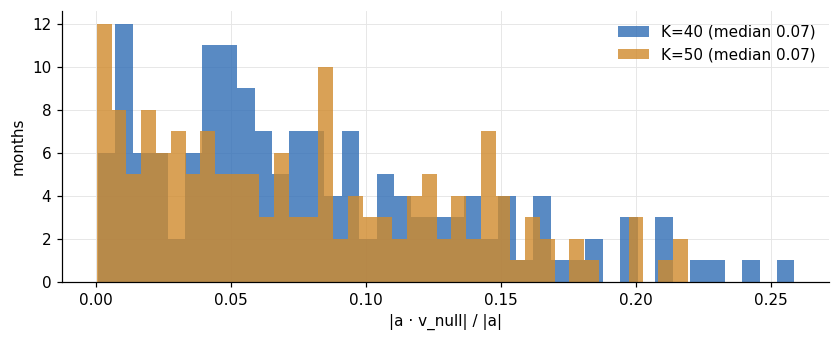

In [4]:
def null_share(k):
    fr, _, _, holdings, _ = panels[k]
    A = runs[(k, "all K")]["weights_df"].drop("DATE").to_numpy()
    start = len(holdings) - len(A)
    out = []
    for i, a in enumerate(A):
        v = np.linalg.svd(holdings[start + i][1], full_matrices=False)[2][-1]
        out.append(abs(a @ v) / np.linalg.norm(a))
    return np.array(out)
fig, ax = plt.subplots(figsize=(9, 3.2))
for k, color in [(40, BLUE), (50, "#d08a2c")]:
    s = null_share(k)
    ax.hist(s, bins=40, alpha=0.8, color=color, label=f"K={k} (median {np.median(s):.2f})")
ax.set_xlabel("|a · v_null| / |a|"); ax.set_ylabel("months"); ax.legend(frameon=False); plt.show()

## Month-to-month change in factor weights: all K vs K−1

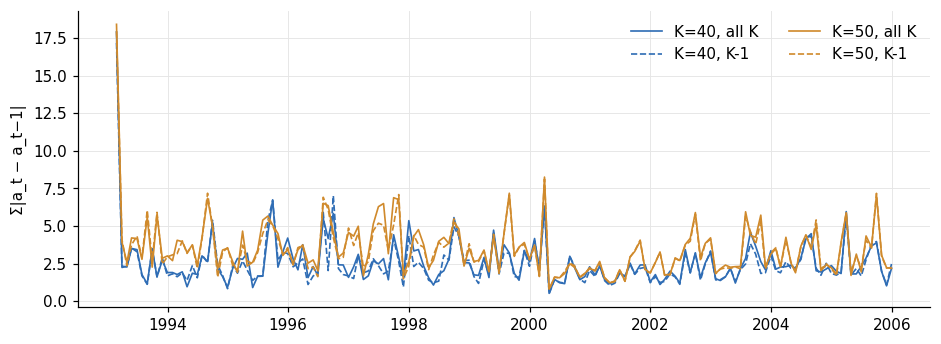

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for (k, which), r in runs.items():
    d = r["returns_df"]
    ax.plot(d["DATE"].cast(pl.String).str.to_date("%Y%m%d"), d["factor_turnover"], lw=1.1,
            label=f"K={k}, {which}", color={40: BLUE, 50: "#d08a2c"}[k], ls="-" if which == "all K" else "--")
ax.set_ylabel("Σ|a_t − a_t−1|"); ax.legend(frameon=False, ncol=2); plt.show()

## Combined portfolio: largest single-stock weight and stock gross (share of capital)

In [6]:
pl.DataFrame([{"K": k, "factors": which,
               "max_stock_weight_median": r["returns_df"]["max_stock_weight"].median(),
               "max_stock_weight_worst": r["returns_df"]["max_stock_weight"].max(),
               "stock_gross_median": r["returns_df"]["stock_gross"].median(),
               "realised_vol": r["metrics"]["Annualized Volatility"], "target_vol": TARGET_VOL}
              for (k, which), r in runs.items()])

K,factors,max_stock_weight_median,max_stock_weight_worst,stock_gross_median,realised_vol,target_vol
i64,str,f64,f64,f64,f64,f64
40,"""all K""",0.0047,0.0069,3.0000,0.1058,0.1000
40,"""K-1""",0.0047,0.0069,3.0000,0.1065,0.1000
50,"""all K""",0.0049,0.0067,3.0000,0.1043,0.1000
50,"""K-1""",0.0049,0.0067,3.0000,0.1051,0.1000
